In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [7]:
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name="LDC - Direct Emissions", skiprows=3)
df.head()

,Facility Id,FRS Id,Facility Name,State where Emissions Occur,Reported City,Reported State,Reported Zip Code,Reported Address,Reported County,Reported Latitude,...,2020 Total reported direct emissions from Local Distribution Companies,2019 Total reported direct emissions from Local Distribution Companies,2018 Total reported direct emissions from Local Distribution Companies,2017 Total reported direct emissions from Local Distribution Companies,2016 Total reported direct emissions from Local Distribution Companies,2015 Total reported direct emissions from Local Distribution Companies,2014 Total reported direct emissions from Local Distribution Companies,2013 Total reported direct emissions from Local Distribution Companies,2012 Total reported direct emissions from Local Distribution Companies,2011 Total reported direct emissions from Local Distribution Companies
0,1008026,1.100712e+11,Ameren Illinois,IL,Peoria,IL,61602,300 Liberty Street,PEORIA COUNTY,40.690450,...,74939.996,74762.846,99558.146,74961.100,73739.346,105051.594,75801.60,75662.2,75480.25,73414.44
1,1004034,1.100712e+11,Ameren Missouri,MO,St. Louis,MO,63103,1901 Chouteau Avenue,ST. LOUIS CITY,38.620667,...,14759.550,14674.950,13714.750,13668.500,13556.800,13459.200,13412.60,13353.6,13736.25,13271.75
2,1004975,1.100712e+11,Arkansas Oklahoma Gas Corp (AR),AR,Fort Smith,AR,72903,5030 South S Street,SEBASTIAN COUNTY,35.363559,...,NaN,NaN,NaN,8961.200,9771.050,11131.700,10870.50,10821.8,11025.50,11509.60
3,1006481,NaN,Arkansas Oklahoma Gas Corp (OK),OK,Fort Smith,AR,72903,5030 South S Street,NaN,35.363530,...,NaN,NaN,NaN,2983.450,2977.350,3220.500,2447.55,3111.7,3129.45,3426.50
4,1007872,1.100712e+11,Atlanta Gas Light Company,GA,Atlanta,GA,30309,Ten Peachtree Place,FULTON COUNTY,33.797114,...,165161.150,154525.296,156542.840,154795.438,151902.050,160923.894,155671.85,155513.8,191483.40,217658.90


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  193 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [9]:
df = df.fillna(df.mean(numeric_only=True)) #only numeric columns

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  208 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [17]:
ghg_array = df.to_numpy()

emissions_only = ghg_array[:, 13:].astype(float)

column_sums = np.sum(emissions_only, axis=0)
print(column_sums)

[15097669.60264968 15169067.20198758 15069159.34639521 15477887.22968675
 15793386.25532121 16388006.10770731 16269222.85155556 17054300.99031579
 17108074.81419209 16975388.07160221 17918099.25454546 17517858.32148634
 17808374.54933333]


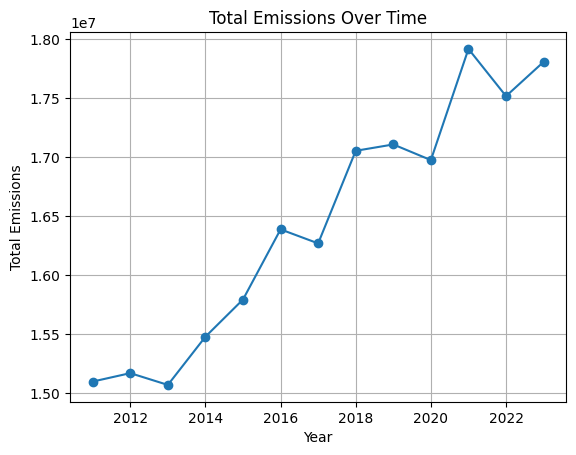

In [20]:
years = np.array([2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

plt.plot(years, column_sums, marker="o")
plt.xlabel('Year')
plt.ylabel('Total Emissions')
plt.title('Total Emissions Over Time')
plt.grid(True)
plt.show()